In [1]:
import pandas as pd
pd.set_option('display.max_columns',100)

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [2]:
df = pd.read_csv('data.csv', on_bad_lines='skip')

In [3]:
df

,password,strength
0,kzde5577,1
1,kino3434,1
2,visi7k1yr,1
3,megzy123,1
4,lamborghin1,1
...,...,...
669635,10redtux10,1
669636,infrared1,1
669637,184520socram,1
669638,marken22a,1


0-WEEK
1-MEDIUM
2-STRONG

In [4]:
df.head()

,password,strength
0,kzde5577,1
1,kino3434,1
2,visi7k1yr,1
3,megzy123,1
4,lamborghin1,1


In [5]:
df.shape

(669640, 2)

In [6]:
df.isnull().sum()

password    1
strength    0
dtype: int64

<Axes: xlabel='strength', ylabel='count'>

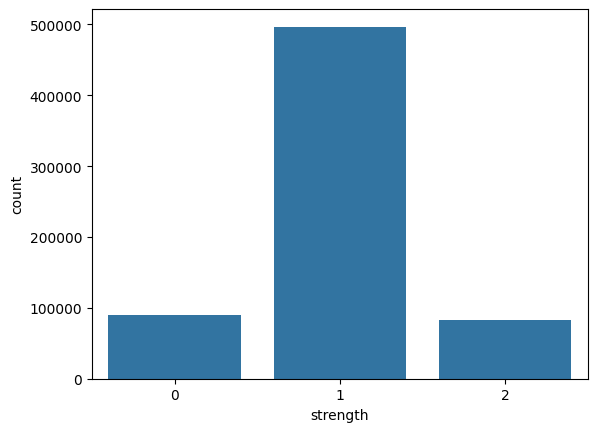

In [7]:
sns.countplot(x=df['strength'])

here in the dataset most recorrds or person medium strength passwords




In [8]:
df = df.dropna(subset=["password"]).copy()

In [9]:
df["strength"].value_counts()

strength
1    496801
0     89701
2     83137
Name: count, dtype: int64

In [10]:
df.groupby("strength")["password"].apply(lambda x: x.str.len().mean())

strength
0     6.549604
1     9.618964
2    15.932497
Name: password, dtype: float64

EDA

In [11]:
import numpy as np

In [12]:
df['password_length'] = df['password'].astype(str).str.len()

In [13]:
df['password_length'].describe()

count    669639.000000
mean          9.991648
std           2.819954
min           1.000000
25%           8.000000
50%           9.000000
75%          11.000000
max         220.000000
Name: password_length, dtype: float64

In [14]:
print("Passwords longer than 50 chars:", (df["password_length"] > 50).sum())
print("Passwords longer than 100 chars:", (df["password_length"] > 100).sum())

Passwords longer than 50 chars: 7
Passwords longer than 100 chars: 4


In [15]:
df.groupby("strength")["password_length"].describe()

,count,mean,std,min,25%,50%,75%,max
strength,,,,,,,,
0,89701.0,6.549604,0.509952,1.0,6.0,7.0,7.0,7.0
1,496801.0,9.618964,1.343117,8.0,9.0,9.0,10.0,13.0
2,83137.0,15.932497,2.020979,14.0,16.0,16.0,16.0,220.0


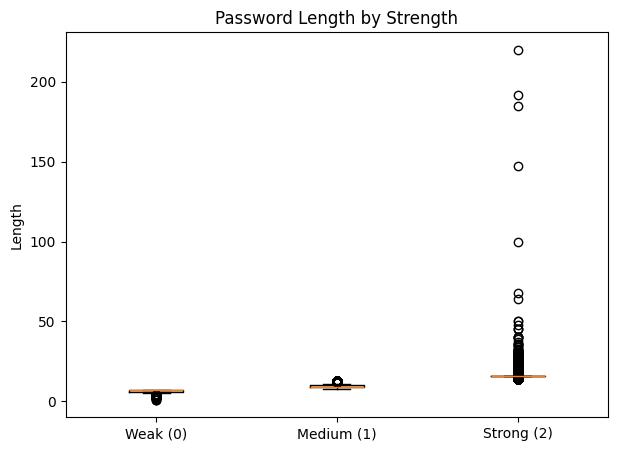

In [16]:
plt.figure(figsize=(7,5))
plt.boxplot(
    [df[df["strength"]==0]["password_length"],
     df[df["strength"]==1]["password_length"],
     df[df["strength"]==2]["password_length"]],
    labels=["Weak (0)", "Medium (1)", "Strong (2)"]
)
plt.title("Password Length by Strength")
plt.ylabel("Length")
plt.show()

In [17]:
passwords = df["password"].astype(str)

In [18]:
df["n_digit"]  = passwords.str.count(r'\d')
df["n_lower"]  = passwords.str.count(r'[a-z]')
df["n_upper"]  = passwords.str.count(r'[A-Z]')
df["n_symbol"] = passwords.str.count(r"[^a-zA-Z0-9]")

In [19]:
df["unique_ratio"] = passwords.apply(lambda x: len(set(x))) / df["password_length"]

In [20]:
df["unique_ratio"] = df["unique_ratio"].fillna(0)

In [21]:
df.head()

,password,strength,password_length,n_digit,n_lower,n_upper,n_symbol,unique_ratio
0,kzde5577,1,8,4,4,0,0,0.750000
1,kino3434,1,8,4,4,0,0,0.750000
2,visi7k1yr,1,9,2,7,0,0,0.888889
3,megzy123,1,8,3,5,0,0,1.000000
4,lamborghin1,1,11,1,10,0,0,1.000000


In [22]:
df.groupby("strength")[["n_digit","n_lower","n_upper","n_symbol","unique_ratio"]].mean()

,n_digit,n_lower,n_upper,n_symbol,unique_ratio
strength,,,,,
0,1.774741,4.673181,0.078238,0.023445,0.880941
1,3.449599,6.068683,0.081548,0.019134,0.854940
2,3.100509,6.771907,5.823460,0.236621,0.863091


In [23]:
df["complexity_score"] = (df["n_digit"] * 1) + \
                         (df["n_upper"] * 2) + \
                         (df["n_symbol"] * 3)

In [24]:
df["complexity_density"] = df["complexity_score"] / df["password_length"]

In [25]:
df[["password", "password_length", "complexity_score"]].head()

,password,password_length,complexity_score
0,kzde5577,8,4
1,kino3434,8,4
2,visi7k1yr,9,2
3,megzy123,8,3
4,lamborghin1,11,1


In [26]:
df.groupby("strength")[["complexity_score","complexity_density"]].describe()

complexity_score                                                     \
                    count       mean       std  min   25%   50%   75%    max   
strength                                                                       
0                 89701.0   2.001550  1.620489  0.0   1.0   2.0   2.0   21.0   
1                496801.0   3.670097  2.551913  1.0   2.0   3.0   4.0   35.0   
2                 83137.0  15.457293  5.196892  3.0  13.0  16.0  19.0  191.0   

         complexity_density                                                    \
                      count      mean       std       min       25%       50%   
strength                                                                        
0                   89701.0  0.311023  0.259220  0.000000  0.142857  0.285714   
1                  496801.0  0.382606  0.257462  0.076923  0.222222  0.333333   
2                   83137.0  0.972873  0.310141  0.100000  0.785714  1.000000   

                              
               75%       max  
strength                      
0         0.333333  3.000000  
1         0.454545  2.875000  
2         1.187500  2.444444

CLEANING

In [27]:
df = df.dropna().copy()

In [28]:
df["password"] = df["password"].astype(str)
df["strength"] = df["strength"].astype(int)

In [29]:
df["strength"].value_counts(normalize=True)

strength
1    0.741894
0    0.133954
2    0.124152
Name: proportion, dtype: float64

In [30]:
structural_features = ["password_length", "unique_ratio"]
char_counts         = ["n_digit", "n_lower", "n_upper", "n_symbol"]
complexity_metrics  = ["complexity_density"]

In [31]:
selected_features = structural_features + char_counts + complexity_metrics

In [32]:
x = df[selected_features].copy()
y = df["strength"].copy()

In [33]:
x = x.fillna(0)

In [34]:
x.head()

,password_length,unique_ratio,n_digit,n_lower,n_upper,n_symbol,complexity_density
0,8,0.750000,4,4,0,0,0.500000
1,8,0.750000,4,4,0,0,0.500000
2,9,0.888889,2,7,0,0,0.222222
3,8,1.000000,3,5,0,0,0.375000
4,11,1.000000,1,10,0,0,0.090909


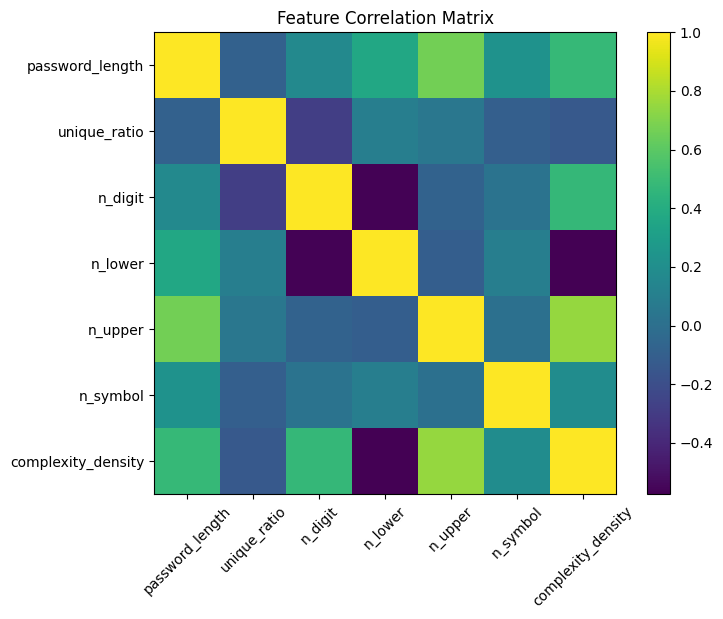

In [35]:
corr = x.corr()

plt.figure(figsize=(8,6))
plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Feature Correlation Matrix")
plt.show()

In [36]:
x_train, x_valid, y_train, y_valid = train_test_split(x,y,test_size=0.15,random_state=42,stratify=y)

In [37]:
y_train.value_counts(normalize=True)
y_valid.value_counts(normalize=True)

strength
1    0.741891
0    0.133953
2    0.124156
Name: proportion, dtype: float64

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [39]:
pw_train = df.loc[x_train.index, "password"]
pw_valid = df.loc[x_valid.index, "password"]


In [40]:
tfidf = TfidfVectorizer(analyzer='char', ngram_range=(2, 3), max_features=1000)

In [41]:
x_train_tfidf = tfidf.fit_transform(pw_train)

In [42]:
x_valid_tfidf = tfidf.transform(pw_valid)

In [43]:
from scipy.sparse import hstack
from scipy.sparse import csr_matrix


x_train_numeric = csr_matrix(x_train.values)
x_valid_numeric = csr_matrix(x_valid.values)

x_train_hybrid = hstack([x_train_tfidf, x_train_numeric])
x_valid_hybrid = hstack([x_valid_tfidf, x_valid_numeric])

print("Hybrid Train Shape:", x_train_hybrid.shape)
print("Hybrid Valid Shape:", x_valid_hybrid.shape)

Hybrid Train Shape: (569193, 1007)
Hybrid Valid Shape: (100446, 1007)


MODEL TRAIN


In [44]:
from sklearn.metrics import accuracy_score, f1_score

In [46]:
LR = LogisticRegression(max_iter=300, class_weight="balanced")

In [47]:
LR.fit(x_train_hybrid, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [48]:
pred = LR.predict(x_valid_hybrid)

In [49]:
accuracy_score(y_valid, pred)

0.9999402664118033

In [50]:
print(classification_report (y_valid, pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13455
           1       1.00      1.00      1.00     74520
           2       1.00      1.00      1.00     12471

    accuracy                           1.00    100446
   macro avg       1.00      1.00      1.00    100446
weighted avg       1.00      1.00      1.00    100446

